# Weak-lensing shear and halo-mass inference

Measure galaxy shapes from the supplied image stamps, stack tangential profiles around the supplied halo catalogue, and infer a common NFW halo mass and source redshift. The inputs are simulated galaxy images.

The full dataset comprises 100,000 galaxy stamps and 100 halo positions. Raw input files are supplied separately and are not included in this repository. Source-position row order must match the FITS image order.

## Select the inputs

Choose one mode before starting Jupyter:

- Set `A6_DATA_DIR` to the directory containing `galaxy_stamps.fits`, `source_positions.txt` and `halo_positions.txt` to run the complete analysis. Generated results go to `outputs/coursework/`.
- Set `A6_RESULTS_DIR` to a directory already produced by `scripts/run_analysis.py` to inspect its saved numerical results. This mode takes precedence if both variables are set; it does not repeat image measurements.

Without either variable, the notebook prints setup guidance and skips the data-dependent cells. The synthetic walkthrough runs without external inputs.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from weak_lensing import analysis, pipeline, plotting

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_DIR = os.environ.get("A6_DATA_DIR")
RESULTS_DIR = os.environ.get("A6_RESULTS_DIR")
results = None
summary = None

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180})

In [2]:
if RESULTS_DIR:
    result_path = Path(RESULTS_DIR).expanduser()
    print("Loading saved numerical results; image measurement is not repeated.")
elif DATA_DIR:
    result_path = ROOT / "outputs" / "coursework"
    pipeline.run_coursework(Path(DATA_DIR).expanduser(), result_path)
    print("Full analysis complete; generated results are in outputs/coursework/.")
else:
    result_path = None
    print("Set A6_DATA_DIR for a full run, or A6_RESULTS_DIR to inspect a previous run.")

if result_path is not None:
    summary = json.loads((result_path / "summary.json").read_text())
    if summary.get("input_kind") != "Supplied coursework simulations":
        raise ValueError("Use coursework results here; synthetic results belong in notebook 01.")
    with np.load(result_path / "analysis_results.npz", allow_pickle=False) as archive:
        results = {name: archive[name] for name in archive.files}
    print(f"Sources analysed: {summary['n_sources']:,}; halos: {summary['n_halos']:,}")
    print(f"Source subset: {summary['source_subset']}; inference grid: {summary['grid_size']} × {summary['grid_size']}")

Loading saved numerical results; image measurement is not repeated.
Sources analysed: 100,000; halos: 100
Source subset: False; inference grid: 120 × 120


## Shape measurements and radial profiles

The analysis compares unweighted moments, circular Gaussian weighted moments (FWHM 4 pixels), and GalSim HSM adaptive moments. Each estimator retains a row for every source, marking failed measurements as `NaN`; invalid sources are excluded separately for each profile.

The moment estimators use the coursework expression $e_2=Q_{xy}/D$, without the usual factor of two, while HSM uses `observed_shape.g1` and `g2`. These are distinct component conventions. The HSM profile supplies the inference data vector.

Every valid halo–source pair between 100 and 3,600 arcsec is projected tangentially and assigned to one of ten logarithmic bins. Error bars use the sample standard error of pair measurements; this approximation treats reused sources as independent pairs.

Failed shape measurements
  unweighted: 6,837
  weighted  : 4
  hsm       : 0


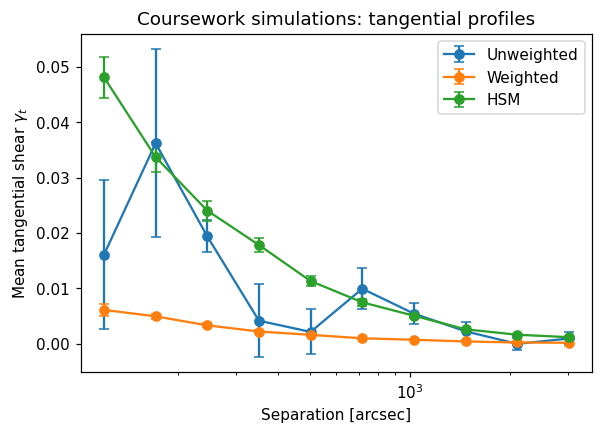

In [3]:
if summary is not None:
    print("Failed shape measurements")
    for name in pipeline.METHODS:
        print(f"  {name:10s}: {summary['invalid_shapes'][name]:,}")

if results is not None:
    profiles = [
        (results["radii_arcsec"], results[f"mean_{name}"],
         results[f"error_{name}"], name.upper() if name == "hsm" else name.capitalize())
        for name in pipeline.METHODS
    ]
    fig, ax = plotting.mean_shear_with_errorbars(profiles)
    ax.set_title("Coursework simulations: tangential profiles")
    plt.show()

## Joint mass–redshift posterior

The Gaussian likelihood compares the HSM profile with NFW tangential shear at bin centres, using independent errors across bins. Concentration is fixed at 4, halo redshift at 0.3, and $(\Omega_m,\Omega_\Lambda)=(0.3,0.7)$.

The default grid contains 120 linearly spaced masses from $3.0\times10^{14}$ to $14.8\times10^{14}\,M_\odot/h$ and 120 source redshifts from 0.31 to 0.8. A uniform prior applies within these ranges. Posterior cell probabilities sum to one; the 68% and 95% contours are density thresholds enclosing those discrete probability fractions.

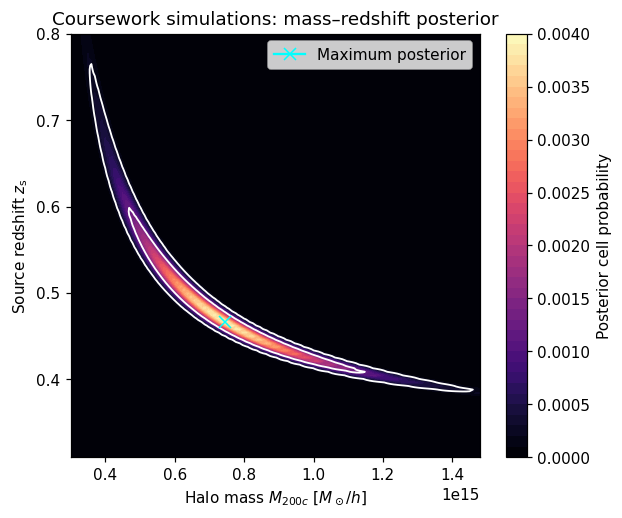

Joint grid maximum: M = 7.462e+14 M_sun/h
Source redshift: 0.466


In [4]:
if results is not None:
    level_68, level_95 = analysis.get_credible_levels(results["joint_posterior"])
    fig, ax = plotting.joint_posterior(
        results["halo_masses_msun_over_h"], results["source_redshifts"],
        results["joint_posterior"], level_68, level_95,
        summary["joint_best_mass_msun_over_h"], summary["joint_best_source_redshift"]
    )
    ax.set_title("Coursework simulations: mass–redshift posterior")
    plt.show()
    print(f"Joint grid maximum: M = {summary['joint_best_mass_msun_over_h']:.3e} M_sun/h")
    print(f"Source redshift: {summary['joint_best_source_redshift']:.3f}")

## Mass posterior at fixed source redshift

Fixing $z_s=0.6$ changes the inference problem: this is a conditional mass posterior, not the joint posterior marginalised over redshift. It uses the same mass grid and is normalised as a density by trapezoidal integration.

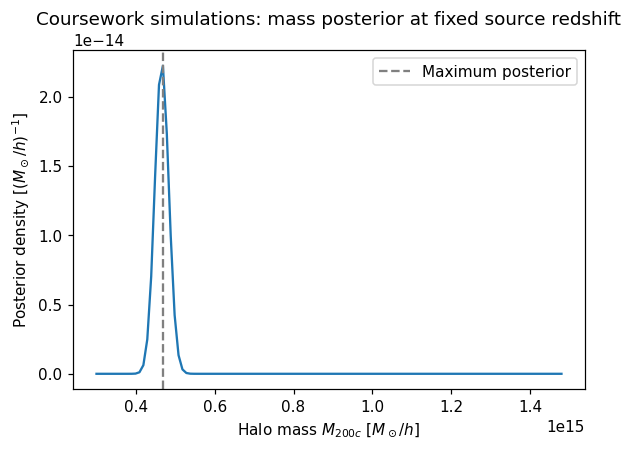

Fixed-redshift grid maximum: M = 4.686e+14 M_sun/h


In [5]:
if results is not None:
    fig, ax = plotting.mass_posterior(
        results["halo_masses_msun_over_h"], results["fixed_z_mass_posterior"],
        summary["fixed_z_best_mass_msun_over_h"], summary["fixed_source_redshift"]
    )
    ax.set_title("Coursework simulations: mass posterior at fixed source redshift")
    plt.show()
    print(f"Fixed-redshift grid maximum: M = {summary['fixed_z_best_mass_msun_over_h']:.3e} M_sun/h")

## Recorded simulation results

The source notebook and report record 6,837 failed unweighted measurements, 4 failed weighted measurements and no failed HSM measurements. Their joint grid maximum is $M=7.462\times10^{14}\,M_\odot/h$, $z_s=0.466$; fixing $z_s=0.6$ gives $M=4.686\times10^{14}\,M_\odot/h$. These values refer to the complete supplied dataset and the default 120 × 120 grid, not to the synthetic example or a source subset.

The mass unit follows GalSim's NFW convention. Limits on interpretation include the moment-component convention, reduced-shape versus shear approximation, finite grid and prior support, bin-centre evaluation, and the independent-pair/diagonal-error assumptions. The analysis does not implement PSF correction or survey-level shear calibration. See `docs/method.md` for details.